# 06 - Sensor design for Belauri: where should a few sensors go?

**Real geography; synthetic emissions and meteorology.** The municipality polygon, the road / built-up / facility geometry and the Nepal outline are real (prepared in `data/belauri`). Every emission rate, the inflow, every wind and all noise are **synthetic**. Candidate sites, layouts and every error below are a **provisional simulation design, not field-validated**: mapped accessibility is not permission, power, security or connectivity, and gaps in OpenStreetMap are not proof that a site is infeasible.

**What runs here (offline, bounded).** The *smoke* profile of the study (`configs/geodesign_smoke.json`: outer domain cropped to a 2 km buffer, T = 7200 s, 2 + 2 + 2 cases, a coarse 3 km candidate lattice, budgets 1 and 3) is executed in this notebook, followed by the smoke profile of the robustness study (`configs/geodesign_robust_smoke.json`). It checks the plumbing and illustrates the outputs; **it is too small for conclusions**. If a production run is present under `results/geodesign` (and `results/geodesign-robust`), its saved tables and figures are shown as well (optional cells).

Terms. *Candidate*: a possible sensor position. *Layout*: a set of candidates (budget = its size). *Greedy*: add one site at a time, always the one that most lowers the design objective: a heuristic, never called optimal. *Total error*: study-area x time weighted RMSE of the reconstructed concentration. *Attribution error*: the same for the local and external parts of the field, each divided by the mean square of that true component (design cases only), then averaged.

In [1]:
import json, tempfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pravah import geodesign as G
from pravah import geodesign_robust as R
from pravah.belauri import draw_map
from pravah.config import load_config
from pravah.inverse import ResponseCache
%matplotlib inline
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
T0 = time.perf_counter()
root = Path.cwd()
while not (root / "configs" / "geodesign_smoke.json").exists() and root != root.parent:
    root = root.parent
LABEL = "Real geography; synthetic emissions and meteorology."
work = Path(tempfile.mkdtemp(prefix="pravah_nb06_"))
cache = ResponseCache()
cfg = load_config(root / "configs" / "geodesign_smoke.json")
print("work dir (temporary):", work.name)

work dir (temporary): pravah_nb06_hshduauz


## 1. Run the smoke design study

Order of the pipeline: candidates, then design and validation ensembles, then alpha (ridge strength) chosen on the **validation** ensemble only, then layouts chosen on the **design** ensemble only, and only then the independent **test** ensemble with fresh noise. Test seeds never influence layouts or alpha.

In [2]:
t0 = time.perf_counter()
main_dir = work / "geodesign"
G.run_geodesign(cfg, main_dir, cache=cache)
print(f"smoke geodesign run: {time.perf_counter() - t0:.0f} s")
st = G.Setup(cfg, cache)
fixed = R.load_fixed_design(main_dir, st)
summ = pd.read_csv(main_dir / "summary.csv")
paired = pd.read_csv(main_dir / "paired.csv")
layouts = pd.read_csv(main_dir / "layouts.csv")
print("files:", sorted(p.name for p in main_dir.iterdir()))

smoke geodesign run: 47 s
files: ['alpha_selected.json', 'candidates.csv', 'candidates.geojson', 'cases.csv', 'config.json', 'design_scores.csv', 'figures', 'git_diff.patch', 'git_status.txt', 'infeasible_budgets.json', 'layouts.csv', 'layouts.geojson', 'noise_levels.csv', 'paired.csv', 'provenance.json', 'summary.csv', 'test_raw.csv', 'timings.json', 'validation_raw.csv']


## 2. Candidate sites

Interior sites are a regular lattice clipped to the municipality polygon; **reference** sites lie outside it but inside Nepal and the simulation domain (at most 2 may be used, counted in the budget). Sites across the national border are *hypothetical* and **excluded by default**.

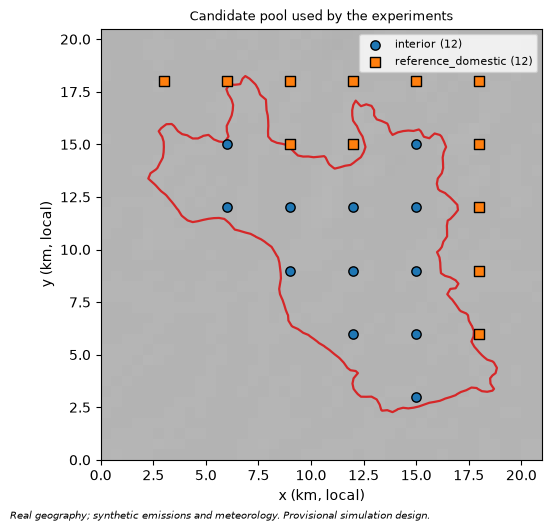

{'interior': 12, 'reference_domestic': 12, 'reference_hypothetical': 12} | hypothetical (excluded by default): 12
            id  category  in_polygon  dist_road_m  dist_facility_m  on_or_near_road
0  int_c003007  interior        True          3.0           1021.0             True
1  int_c004006  interior        True         71.0            614.0             True
2  int_c004007  interior        True         63.0            400.0             True
3  int_c005005  interior        True         69.0           1003.0             True
4  int_c005006  interior        True         97.0            573.0             True
5  int_c005007  interior        True         23.0            616.0             True
assumptions:
  - mapped accessibility is not permission/power/security/connectivity
  - OSM gaps are not absence of feasible sites
  - sites outside the Nepal ADM0 polygon are hypothetical (international access is not assumed)


In [3]:
tab = st.table
fig, ax = plt.subplots(figsize=(6.2, 5.6))
draw_map(ax, st.geo.region, st.res)
cat = np.asarray(st.cands.categories)
for name, col, mk in (("interior", "tab:blue", "o"), ("reference_domestic", "tab:orange", "s")):
    m = cat == name
    ax.scatter(st.cands.x[m] / 1000, st.cands.y[m] / 1000, s=45, c=col, marker=mk, edgecolors="k", label=f"{name} ({m.sum()})", zorder=4)
ax.set_title("Candidate pool used by the experiments", fontsize=9); ax.legend(fontsize=8)
fig.text(0.01, 0.005, LABEL + " Provisional simulation design.", fontsize=7, style="italic")
plt.show()
print(tab["category"].value_counts().to_dict(), "| hypothetical (excluded by default):", int(tab["hypothetical"].sum()))
print(tab[["id", "category", "in_polygon", "dist_road_m", "dist_facility_m", "on_or_near_road"]].head(6).round(0))
print("assumptions:")
for a in G.ASSUMPTIONS:
    print("  -", a)

## 3. Selected sites: spread, greedy_total, greedy_attribution

The same budget and noise fraction; spread is the farthest-point rule (no simulation), the two greedy layouts use the design cases with different objectives.

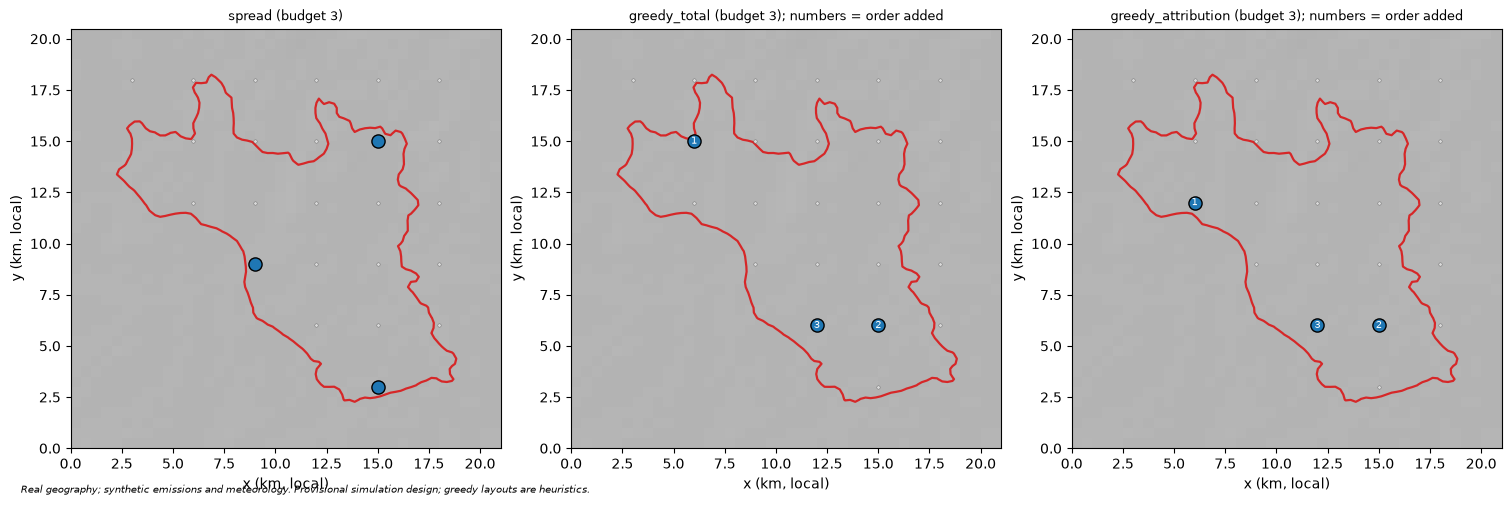

In [4]:
f0 = st.fractions[0]
b = max(st.budgets)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), layout="constrained")
for ax, meth in zip(axes, ("spread", "greedy_total", "greedy_attribution")):
    draw_map(ax, st.geo.region, st.res)
    ax.scatter(st.cands.x / 1000, st.cands.y / 1000, s=6, c="0.85", edgecolors="0.4", linewidths=0.3, zorder=3)
    rec = next(r for r in fixed.layouts if (r.setting, r.regime, r.method, r.budget, r.k) == ("interior_only", "standard", meth, b, 0)
               and r.noise_fraction in (None, f0))
    ax.scatter(st.cands.x[list(rec.layout)] / 1000, st.cands.y[list(rec.layout)] / 1000, s=90, c="tab:blue", edgecolors="k", zorder=5)
    for pos, i in enumerate(rec.order or rec.layout):
        ax.annotate(str(pos + 1) if rec.order else "", (st.cands.x[i] / 1000, st.cands.y[i] / 1000), color="w", fontsize=7, ha="center", va="center", zorder=6)
    ax.set_title(f"{meth} (budget {b}); numbers = order added" if rec.order else f"{meth} (budget {b})", fontsize=9)
fig.text(0.01, 0.005, LABEL + " Provisional simulation design; greedy layouts are heuristics.", fontsize=7, style="italic")
plt.show()

## 4. Error versus number of sensors

Total regional RMSE on the **independent test ensemble** (fresh noise), mean over layouts x cases x noise repetitions; the shaded band is **+/- 1 s.d.** over those rows. It is descriptive: cases and repetitions are not independent draws, so it is never a confidence interval. (Smoke: 2 cases, 2 repetitions.)

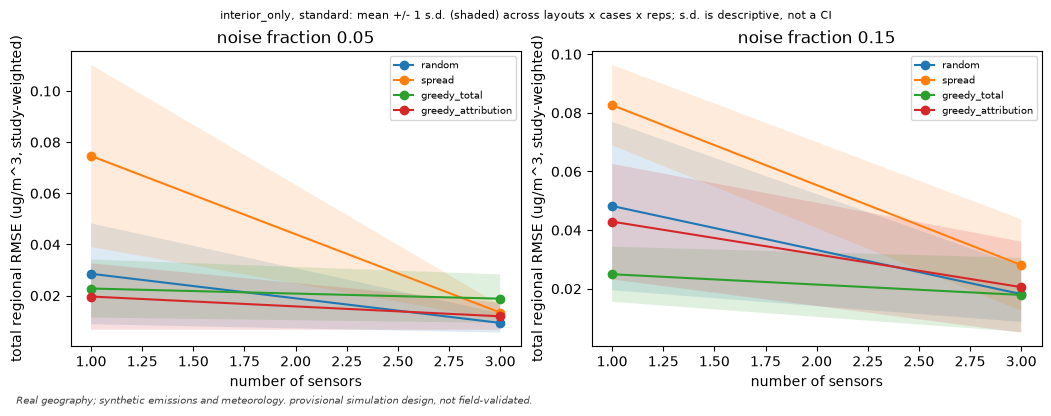

mean_rmse  sd_rmse  mean_rmse_local  mean_rmse_external  mean_attr_err
noise_fraction method             budget                                                                        
0.05           greedy_attribution 1          0.0197   0.0130           0.0161              0.0126         0.3281
                                  3          0.0119   0.0053           0.0102              0.0079         0.2030
               greedy_total       1          0.0228   0.0114           0.0080              0.0225         0.5508
                                  3          0.0188   0.0095           0.0077              0.0181         0.4443
               random             1          0.0285   0.0197           0.0179              0.0181         0.4736
                                  3          0.0093   0.0038           0.0050              0.0069         0.1730
               spread             1          0.0746   0.0356           0.0336              0.0562         1.4520
                                  3          0.0134   0.0029           0.0101              0.0067         0.1828
0.15           greedy_attribution 1          0.0429   0.0197           0.0362              0.0217         0.5962
                                  3          0.0206   0.0155           0.0180              0.0114         0.3033
               greedy_total       1          0.0250   0.0094           0.0115              0.0230         0.5659
                                  3          0.0179   0.0127           0.0128              0.0146         0.3648
               random             1          0.0482   0.0288           0.0385              0.0241         0.6652
                                  3          0.0182   0.0095           0.0095              0.0142         0.3544
               spread             1          0.0826   0.0137           0.0459              0.0680         1.6996
                                  3          0.0281   0.0156           0.0159              0.0190         0.4883

In [5]:
fig = G.fig_error_curves(summ, "interior_only", "standard"); plt.show()
view = summ[(summ.setting == "interior_only") & (summ.regime == "standard") & (summ.alpha_label == "selected")]
display(view.groupby(["noise_fraction", "method", "budget"])[["mean_rmse", "sd_rmse", "mean_rmse_local", "mean_rmse_external", "mean_attr_err"]].mean().round(4))

## 5. Does optimising one objective hurt the other?

`greedy_attribution` minimises the normalised local + external error; `greedy_total` the total field error. Both are scored on **both** metrics. Negative paired differences mean the first method is better; `a_wins_cases` counts the test cases won (a handful in the smoke run).

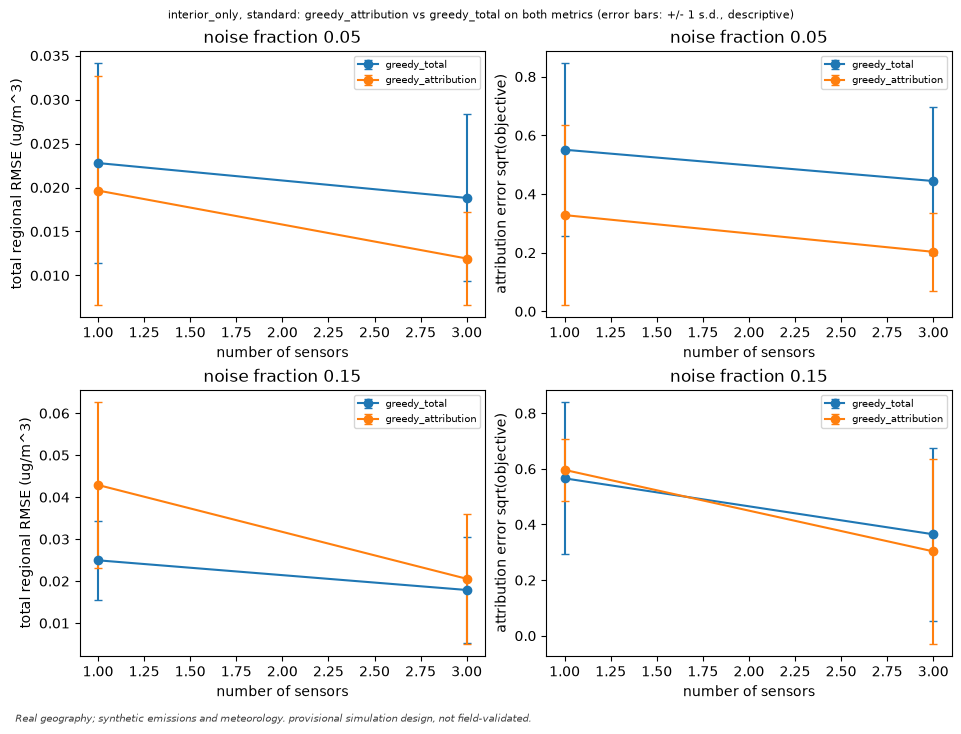

,noise_fraction,budget,metric,mean_diff,sd_diff,n_pairs,a_wins_cases,n_cases
68,0.05,1,rmse,-0.0031,0.0165,4,1,2
69,0.05,3,rmse,-0.0069,0.0139,4,2,2
70,0.15,1,rmse,0.0179,0.0289,4,1,2
71,0.15,3,rmse,0.0027,0.0111,4,1,2
84,0.05,1,attr_err,-0.2227,0.2977,4,2,2
85,0.05,3,attr_err,-0.2413,0.3429,4,2,2
86,0.15,1,attr_err,0.0304,0.2718,4,1,2
87,0.15,3,attr_err,-0.0615,0.2277,4,1,2


In [6]:
fig = G.fig_attribution_vs_total(summ, "interior_only", "standard"); plt.show()
p = paired[(paired.comparison == "greedy_attribution vs greedy_total") & (paired.setting == "interior_only") & (paired.regime == "standard")]
display(p[["noise_fraction", "budget", "metric", "mean_diff", "sd_diff", "n_pairs", "a_wins_cases", "n_cases"]].round(4))

## 6. Value of external reference sites at equal budget

`with_reference` may place up to two sensors outside the polygon (counted in the budget); the comparison is paired with `interior_only` on the same cases and noise.

In [7]:
p = paired[(paired.comparison == "with_reference vs interior_only") & (paired.regime == "standard") & (paired.metric == "rmse")]
display(p[["method_a", "noise_fraction", "budget", "mean_diff", "sd_diff", "n_pairs", "a_wins_cases", "n_cases"]].round(4))
sel = pd.read_csv(main_dir / "test_raw.csv")
sel = sel[(sel.alpha_label == "selected") & (sel.setting == "with_reference") & (sel.regime == "standard")]
print("mean number of reference sites per layout, by method:", sel.groupby("method")["n_reference_sites"].mean().round(2).to_dict())

,method_a,noise_fraction,budget,mean_diff,sd_diff,n_pairs,a_wins_cases,n_cases
132,greedy_attribution,0.05,1,0.0000,0.0000,4,0,2
133,greedy_attribution,0.05,3,-0.0062,0.0055,4,2,2
134,greedy_attribution,0.15,1,0.0000,0.0000,4,0,2
135,greedy_attribution,0.15,3,-0.0055,0.0216,4,2,2
140,greedy_total,0.05,1,0.0000,0.0000,4,0,2
141,greedy_total,0.05,3,0.0007,0.0109,4,1,2
142,greedy_total,0.15,1,0.0337,0.0354,4,0,2
143,greedy_total,0.15,3,0.0049,0.0179,4,1,2
148,random,0.05,1,0.0057,0.0082,4,1,2
149,random,0.05,3,0.0105,0.0063,4,0,2


mean number of reference sites per layout, by method: {'greedy_attribution': 0.75, 'greedy_total': 1.0, 'random': 1.1, 'spread': 1.0}


## 7. Spatially separated validation

A block of the study area (the east third) is held out. In the `block_holdout` regime every layout keeps an **exclusion radius** (2000 m) from the block's evaluation points, so the block error is a true hold-out; budgets that become impossible are reported, not dropped.

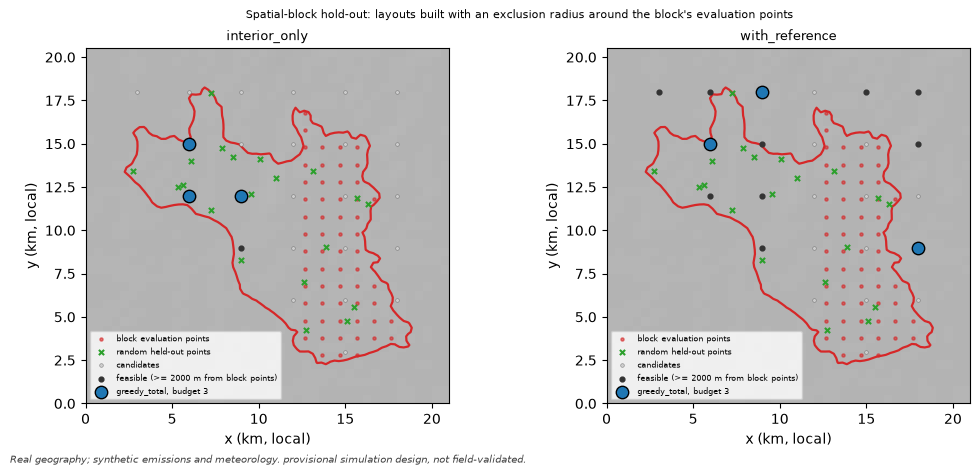

infeasible budgets: {'interior_only|standard': {}, 'interior_only|block_holdout': {}, 'with_reference|standard': {}, 'with_reference|block_holdout': {}}


mean_heldout_block_rmse  mean_heldout_random_rmse  mean_rmse
setting        method             budget                                                              
interior_only  greedy_attribution 1                        0.0157                    0.0203     0.0197
                                  3                        0.0078                    0.0090     0.0095
               greedy_total       1                        0.0108                    0.0247     0.0228
                                  3                        0.0078                    0.0090     0.0095
               random             1                        0.0315                    0.0316     0.0306
                                  3                        0.0112                    0.0092     0.0103
               spread             1                        0.0948                    0.0772     0.0746
                                  3                        0.0129                    0.0106     0.0117
with_reference greedy_attribution 1                        0.0157                    0.0203     0.0197
                                  3                        0.0050                    0.0060     0.0057
               greedy_total       1                        0.0108                    0.0247     0.0228
                                  3                        0.0115                    0.0271     0.0247
               random             1                        0.0383                    0.0374     0.0369
                                  3                        0.0101                    0.0125     0.0130
               spread             1                        0.0948                    0.0772     0.0746
                                  3                        0.0128                    0.0116     0.0118

In [8]:
fig = G.fig_block_map(st, fixed.layouts, f0); plt.show()
print("infeasible budgets:", json.loads((main_dir / "infeasible_budgets.json").read_text())["infeasible"])
v = summ[(summ.regime == "block_holdout") & (summ.alpha_label == "selected") & (summ.noise_fraction == f0)]
display(v.groupby(["setting", "method", "budget"])[["mean_heldout_block_rmse", "mean_heldout_random_rmse", "mean_rmse"]].mean().round(4))

## 8. Robustness of the fixed layouts (smoke version of `geodesign_robust`)

The layouts and the frozen alpha above are **re-used verbatim** (nothing is re-selected) on the regenerated test ensemble (same seeds and noise, so the matched rows are exactly the rows above) under separate conditions: unseen winds (declared as nominal / declared correctly), a hidden wind error, a different boundary time profile, an omitted local facility source, an omitted external Gaussian source, and a 2x finer truth block-averaged to the inference grid. Mismatch need not worsen every draw; paired differences and per-case counts are reported.

In [9]:
t0 = time.perf_counter()
rcfg = load_config(root / "configs" / "geodesign_robust_smoke.json")
rob_dir = work / "robust"
res = R.run_geodesign_robust(rcfg, rob_dir, layouts_from=main_dir, cache=cache)
print(f"smoke robustness run (includes refinement): {time.perf_counter() - t0:.0f} s")
ps = pd.read_csv(rob_dir / "paired_mismatch.csv")
x = ps[(ps.metric == "rmse") & (ps.method == "greedy_total") & (ps.setting == "interior_only") & (ps.noise_fraction == f0)]
display(x[["condition", "budget", "mean_matched", "mean_condition", "mean_diff", "sd_diff", "n_cases_worse", "n_cases"]].round(4))
cases = pd.read_csv(rob_dir / "cases.csv")
display(cases[["case", "condition", "truth_wind", "nominal_wind", "max_courant_truth", "unmodelled_emission_share"]].round(3))
print("matched rows equal the main run's:", json.loads((rob_dir / "provenance.json").read_text())["extra"]["matched_vs_main_test_raw"])

smoke robustness run (includes refinement): 144 s


,condition,budget,mean_matched,mean_condition,mean_diff,sd_diff,n_cases_worse,n_cases
23,boundary_time_profile,1,0.0228,0.0230,0.0002,0.0006,1,2
34,boundary_time_profile,3,0.0188,0.0189,0.0001,0.0003,1,2
391,hidden_wind_error,1,0.0228,0.0307,0.0080,0.0034,2,2
402,hidden_wind_error,3,0.0188,0.0298,0.0110,0.0062,2,2
759,omitted_external,1,0.0228,0.0232,0.0004,0.0004,2,2
770,omitted_external,3,0.0188,0.0197,0.0009,0.0011,2,2
1127,omitted_facility,1,0.0228,0.0300,0.0073,0.0007,2,2
1138,omitted_facility,3,0.0188,0.0212,0.0023,0.0029,2,2
1495,refined_truth,1,0.0228,0.0247,0.0020,0.0009,2,2
1506,refined_truth,3,0.0188,0.0236,0.0048,0.0011,2,2


,case,condition,truth_wind,nominal_wind,max_courant_truth,unmodelled_emission_share
0,t0,matched,t=0s from 258.2 deg at 1.54 m/s,t=0s from 258.2 deg at 1.54 m/s,0.308,0.000
1,t1,matched,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,0.473,0.000
2,t0,unseen_wind,t=0s from 247.5 deg at 2.88 m/s,t=0s from 258.2 deg at 1.54 m/s,0.575,0.000
3,t1,unseen_wind,t=0s from 292.5 deg at 3.15 m/s;t=3600s from 157.5 deg a...,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,0.682,0.000
4,t0,unseen_wind_declared,t=0s from 247.5 deg at 2.88 m/s,t=0s from 258.2 deg at 1.54 m/s,0.575,0.000
5,t1,unseen_wind_declared,t=0s from 292.5 deg at 3.15 m/s;t=3600s from 157.5 deg a...,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,0.682,0.000
6,t0,hidden_wind_error,t=0s from 243.2 deg at 1.85 m/s,t=0s from 258.2 deg at 1.54 m/s,0.370,0.000
7,t1,hidden_wind_error,t=0s from 246.4 deg at 2.84 m/s;t=3600s from 130.4 deg a...,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,0.568,0.000
8,t0,boundary_time_profile,t=0s from 258.2 deg at 1.54 m/s,t=0s from 258.2 deg at 1.54 m/s,0.308,0.000
9,t1,boundary_time_profile,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,t=0s from 261.4 deg at 2.37 m/s;t=3600s from 145.4 deg a...,0.473,0.000


matched rows equal the main run's: {'compared': True, 'n_rows': 256, 'n_main_rows_selected': 512, 'max_relative_difference': 2.2949236470264037e-13}


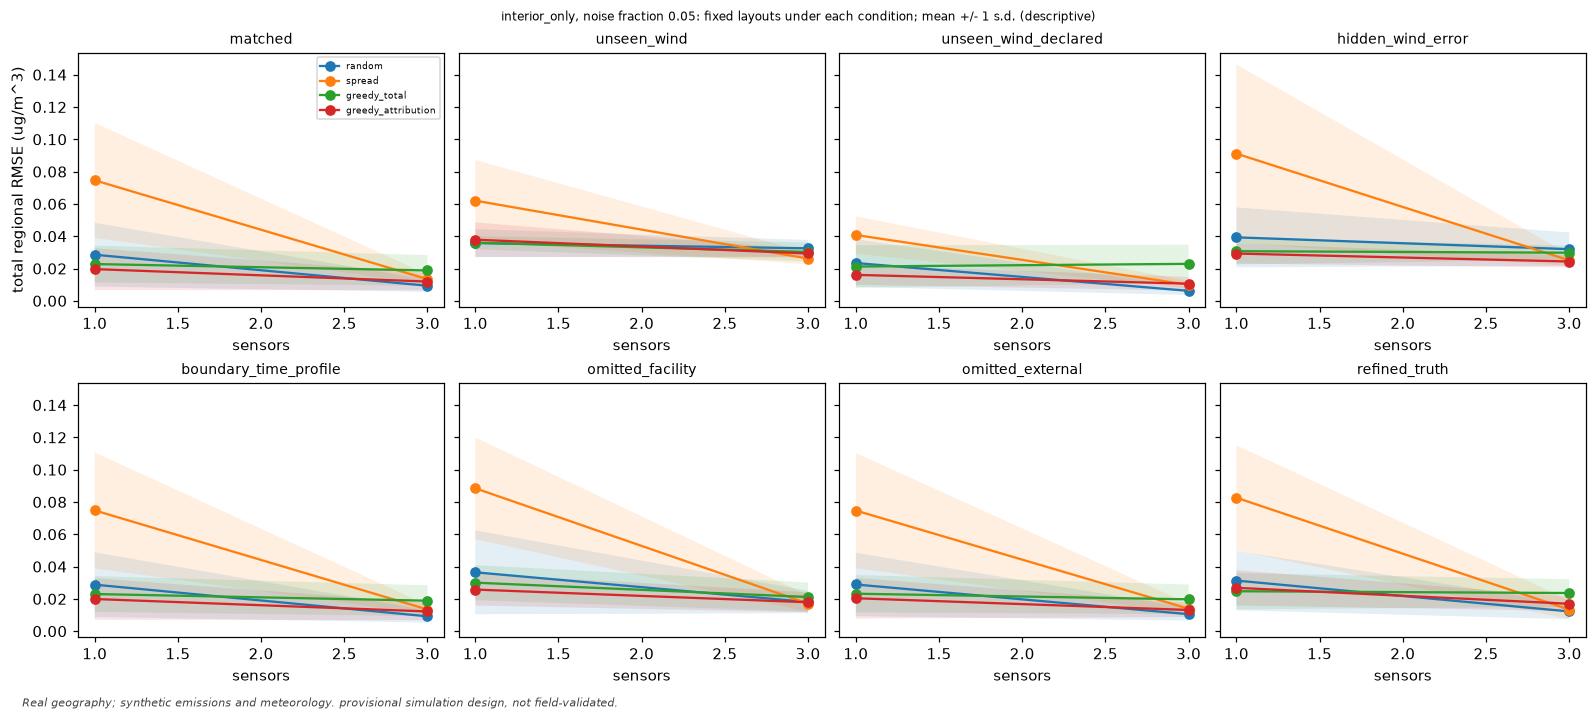

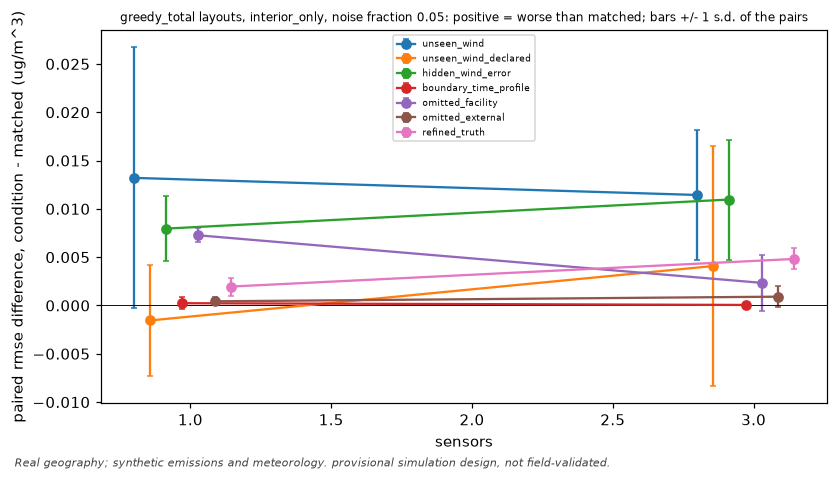

Does greedy_total still beat spread under each condition? (negative = yes)


,condition,budget,mean_diff,mean_diff_matched,same_sign_as_matched,a_wins_cases,n_cases
0,unseen_wind,1,-0.0260,-0.0518,True,2,2
1,unseen_wind,3,0.0041,0.0054,True,0,2
96,unseen_wind_declared,1,-0.0195,-0.0518,True,2,2
97,unseen_wind_declared,3,0.0130,0.0054,True,0,2
192,hidden_wind_error,1,-0.0604,-0.0518,True,2,2
193,hidden_wind_error,3,0.0047,0.0054,True,0,2
288,boundary_time_profile,1,-0.0518,-0.0518,True,2,2
289,boundary_time_profile,3,0.0055,0.0054,True,0,2
384,omitted_facility,1,-0.0584,-0.0518,True,2,2
385,omitted_facility,3,0.0041,0.0054,True,0,2


In [10]:
display(Image(filename=str(rob_dir / "figures" / "rmse_by_condition_interior_only.png")))
display(Image(filename=str(rob_dir / "figures" / "paired_difference.png")))
con = pd.read_csv(rob_dir / "ranking_changes.csv")
c = con[(con.comparison == "greedy_total vs spread") & (con.metric == "rmse") & (con.setting == "interior_only") & (con.noise_fraction == f0)]
print("Does greedy_total still beat spread under each condition? (negative = yes)")
display(c[["condition", "budget", "mean_diff", "mean_diff_matched", "same_sign_as_matched", "a_wins_cases", "n_cases"]].round(4))

### Identifiability flags cannot detect a wrong model

The flags (`rank_deficient`, `weakly_constrained`, `unidentifiable:*`, `confounded:*`) are computed from the operator (the sensor sites and the model's responses) and sigma. They do not look at the data, so under a wrong wind, a different boundary profile or an omitted source they stay exactly as in the matched case while the error moves. The table puts the flagged fraction next to the error ratio.

In [11]:
fl = pd.read_csv(rob_dir / "flags_vs_error.csv")
display(fl[(fl.method == "greedy_total")][["condition", "budget", "frac_flagged", "frac_flagged_matched", "frac_flags_equal_matched", "mean_rmse", "mean_rmse_matched", "rmse_ratio_to_matched"]].round(3))

,condition,budget,frac_flagged,frac_flagged_matched,frac_flags_equal_matched,mean_rmse,mean_rmse_matched,rmse_ratio_to_matched
2,boundary_time_profile,1,1.0,1.0,1.000,0.032,0.032,1.000
3,boundary_time_profile,3,1.0,1.0,1.000,0.020,0.020,1.001
10,hidden_wind_error,1,1.0,1.0,1.000,0.038,0.032,1.176
11,hidden_wind_error,3,1.0,1.0,1.000,0.031,0.020,1.587
18,matched,1,1.0,1.0,1.000,0.032,0.032,1.000
19,matched,3,1.0,1.0,1.000,0.020,0.020,1.000
26,omitted_external,1,1.0,1.0,1.000,0.037,0.032,1.141
27,omitted_external,3,1.0,1.0,1.000,0.022,0.020,1.128
34,omitted_facility,1,1.0,1.0,1.000,0.040,0.032,1.246
35,omitted_facility,3,1.0,1.0,1.000,0.022,0.020,1.092


## 9. Numerical-refinement sensitivity

Two checks. (i) Layouts chosen on the 500 m problem are evaluated against a 250 m / 50 s truth (the `refined_truth` condition above; sensors read the fine field, the regional error uses its 500 m block average). Because the truth uses the same scheme on a finer mesh, this is a **lower bound** on the inverse-crime effect: the matched experiments share their numerics, and the contrast shows how much of the matched accuracy is that. (ii) Greedy layouts are **re-selected on the 250 m model** (here 1 design case, budgets 1 and 3) and compared with the 500 m layouts (Jaccard index, nearest-site distance) and on the same fine test truth. At production size each 250 m response set is about 8 solves of ~30 s.

,setting,method,budget,noise_fraction,jaccard,n_shared_sites,mean_nearest_site_distance_m,max_nearest_site_distance_m
0,interior_only,greedy_total,1,0.05,1.0,1,0.00,0.00
1,interior_only,greedy_total,3,0.05,0.5,2,1500.00,6000.00
2,interior_only,greedy_attribution,1,0.05,1.0,1,0.00,0.00
3,interior_only,greedy_attribution,3,0.05,0.5,2,1000.00,3000.00
4,interior_only,greedy_total,1,0.15,0.0,0,10816.65,10816.65
5,interior_only,greedy_total,3,0.15,0.0,0,3207.11,4242.64
6,interior_only,greedy_attribution,1,0.15,0.0,0,3000.00,3000.00
7,interior_only,greedy_attribution,3,0.15,0.2,1,2207.11,4242.64
8,with_reference,greedy_total,1,0.05,0.0,0,3000.00,3000.00
9,with_reference,greedy_total,3,0.05,0.0,0,4414.21,6000.00


,setting,noise_fraction,method,budget,mean_500m,mean_250m,mean_diff_250m_minus_500m,cases_won_by_250m_layouts,n_cases
0,interior_only,0.05,greedy_attribution,1,0.0210,0.0210,0.0000,0,2
4,interior_only,0.05,greedy_attribution,3,0.0130,0.0113,-0.0017,1,2
8,interior_only,0.05,greedy_total,1,0.0247,0.0247,0.0000,0,2
12,interior_only,0.05,greedy_total,3,0.0207,0.0153,-0.0055,2,2
16,interior_only,0.15,greedy_attribution,1,0.0457,0.0279,-0.0178,1,2
20,interior_only,0.15,greedy_attribution,3,0.0216,0.0286,0.0070,0,2
24,interior_only,0.15,greedy_total,1,0.0279,0.0154,-0.0124,2,2
28,interior_only,0.15,greedy_total,3,0.0195,0.0185,-0.0010,1,2
32,with_reference,0.05,greedy_attribution,1,0.0210,0.0543,0.0333,0,2
36,with_reference,0.05,greedy_attribution,3,0.0056,0.0205,0.0149,0,2


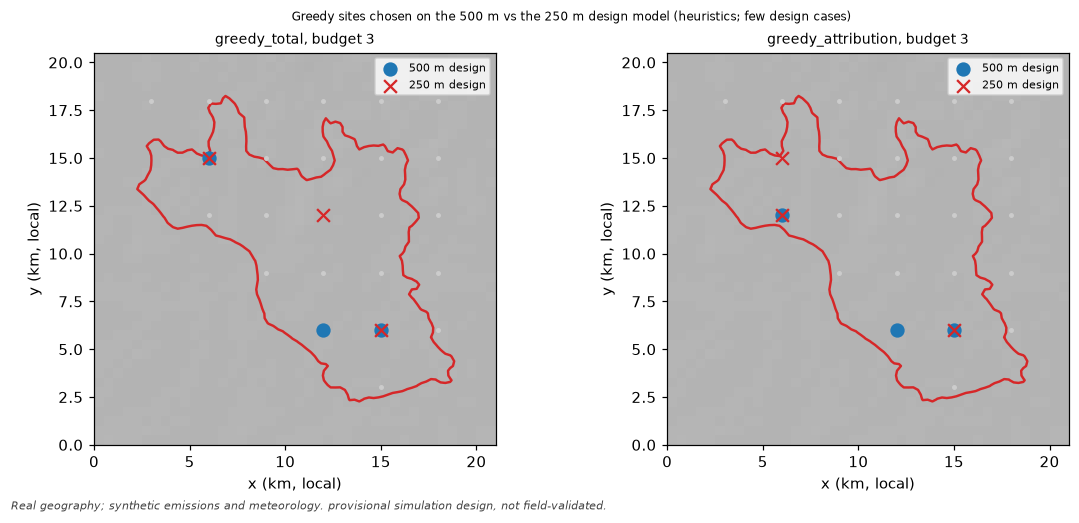

,mesh,dx_m,dt_s,speed_m_s,peclet,courant,K_eff_over_K
9,design,500.0,100.0,0.8,4.00,0.16,2.39
10,design,500.0,100.0,1.5,7.50,0.30,4.88
11,design,500.0,100.0,2.5,12.50,0.50,9.38
12,design,500.0,100.0,3.5,17.50,0.70,14.88
23,refined,250.0,50.0,0.8,2.00,0.16,1.47
24,refined,250.0,50.0,1.5,3.75,0.30,2.53
25,refined,250.0,50.0,2.5,6.25,0.50,4.70
26,refined,250.0,50.0,3.5,8.75,0.70,7.44


The physical K is not tuned.  The baseline scheme (exponential convection + backward Euler) adds numerical spreading estimated by geo.scenarios.numerical_diffusion_estimate (K_eff/K = 1 + excess, wind along a grid axis, a scalar-speed approximation for oblique winds); it is reported separately from K and is part of every forward model, truth and inference alike in the matched experiments.


In [12]:
ov = pd.read_csv(rob_dir / "refinement_overlap.csv")
display(ov[["setting", "method", "budget", "noise_fraction", "jaccard", "n_shared_sites", "mean_nearest_site_distance_m", "max_nearest_site_distance_m"]].round(2))
gap = pd.read_csv(rob_dir / "refinement_gap.csv")
display(gap[gap.metric == "rmse"][["setting", "noise_fraction", "method", "budget", "mean_500m", "mean_250m", "mean_diff_250m_minus_500m", "cases_won_by_250m_layouts", "n_cases"]].round(4))
display(Image(filename=str(rob_dir / "figures" / "refinement_sites.png")))
nd = pd.read_csv(rob_dir / "numerical_diffusion.csv")
display(nd[nd.speed_label.str.startswith("reference")][["mesh", "dx_m", "dt_s", "speed_m_s", "peclet", "courant", "K_eff_over_K"]].round(2))
print(json.loads((rob_dir / "numerical_diffusion.json").read_text())["note"])

## 10. Identifiability and prior dependence

alpha is the ridge strength in scaled units, chosen on the validation ensemble only; the test results are also given for alpha = 0 (no prior) and a strong prior (alpha = 1000, shrinks towards the prior mean 0). A large gap between the rows shows how much the prior carries. Identifiability flags are reported per row.

In [13]:
alpha = json.loads((main_dir / "alpha_selected.json").read_text())
print("selected alpha by noise fraction:", alpha["alpha_by_noise_fraction"], "| uses test ensemble:", alpha["uses_test_ensemble"])
v = summ[(summ.setting == "interior_only") & (summ.regime == "standard") & (summ.method == "greedy_total") & (summ.noise_fraction == f0)]
display(v.pivot_table(index="budget", columns="alpha_label", values="mean_rmse").round(4))
d = summ[(summ.alpha_label == "selected") & (summ.regime == "standard")]
print("share of selected-alpha rows with an identifiability flag, by budget:")
display(d.groupby("budget")["frac_rows_id_flagged"].mean().round(2).to_frame())

selected alpha by noise fraction: {'0.05': 0.01, '0.15': 0.01} | uses test ensemble: False


alpha_label,alpha_zero,selected,strong_prior
budget,,,
1,2.2842,0.0228,0.1039
3,0.0514,0.0188,0.1038


share of selected-alpha rows with an identifiability flag, by budget:


,frac_rows_id_flagged
budget,
1,1.0
3,1.0


## 11. Production results (optional)

Shown only if `results/geodesign` (and `results/geodesign-robust`) exist and are complete; otherwise this cell does nothing.

production study: geodesign | 500 layouts


noise_fraction               0.05                                            0.15                             
method         greedy_attribution greedy_total  random  spread greedy_attribution greedy_total  random  spread
budget                                                                                                        
1                          0.0105       0.0223  0.0250  0.0148             0.0625       0.0366  0.0422  0.0285
2                          0.0065       0.0093  0.0135  0.0117             0.0298       0.0174  0.0227  0.0214
3                          0.0054       0.0052  0.0103  0.0058             0.0212       0.0156  0.0182  0.0158
5                          0.0037       0.0035  0.0067  0.0051             0.0086       0.0108  0.0128  0.0116
8                          0.0033       0.0027  0.0033  0.0032             0.0079       0.0083  0.0083  0.0082

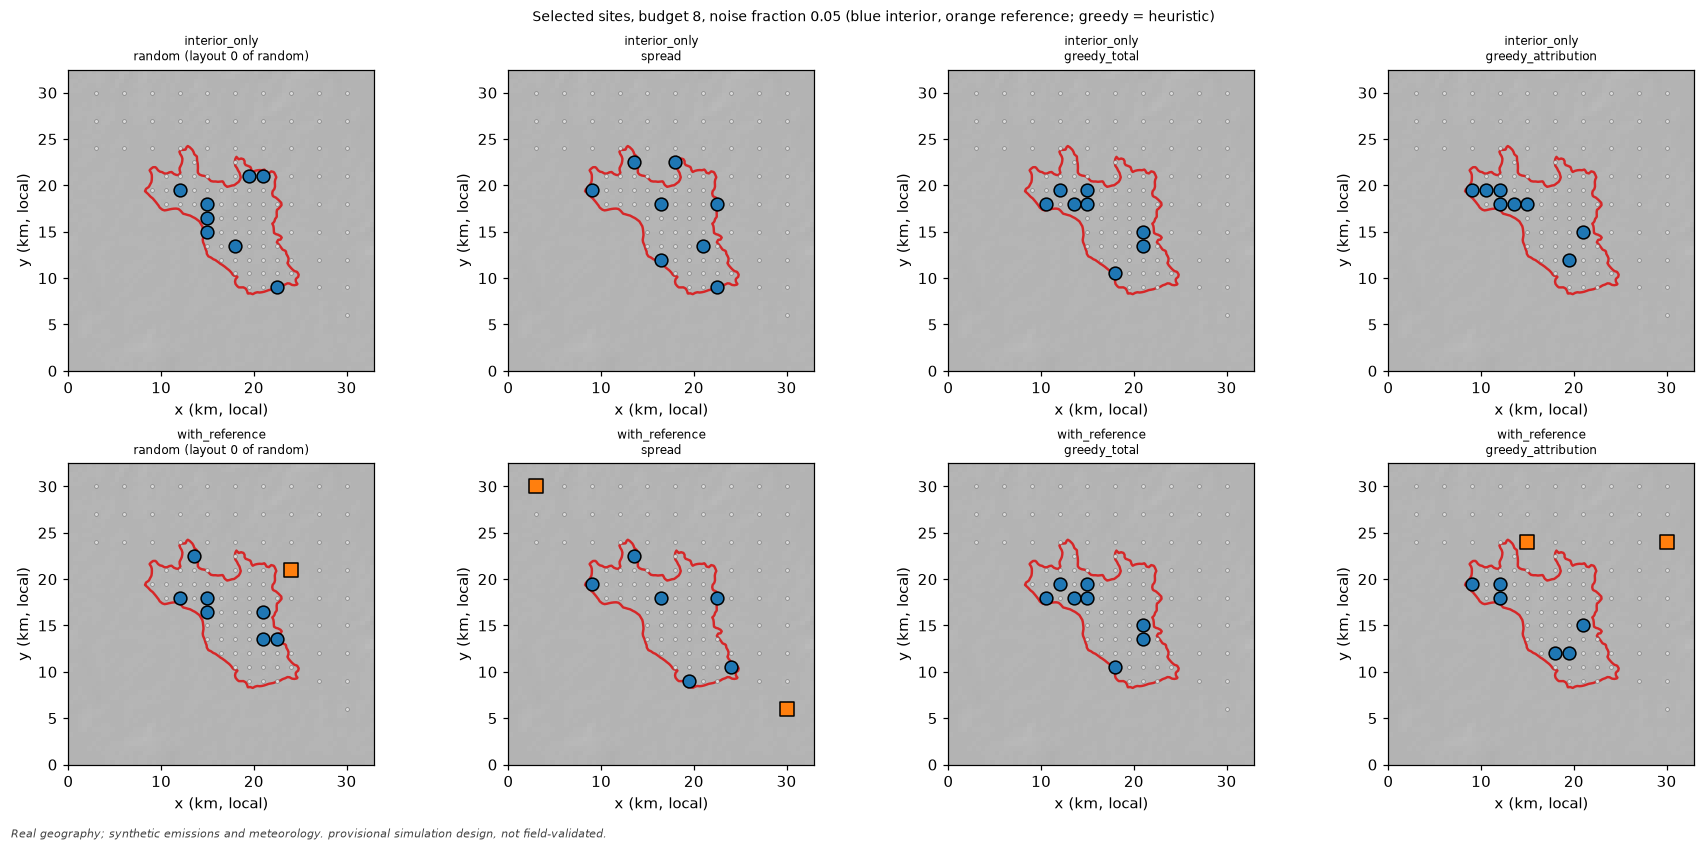

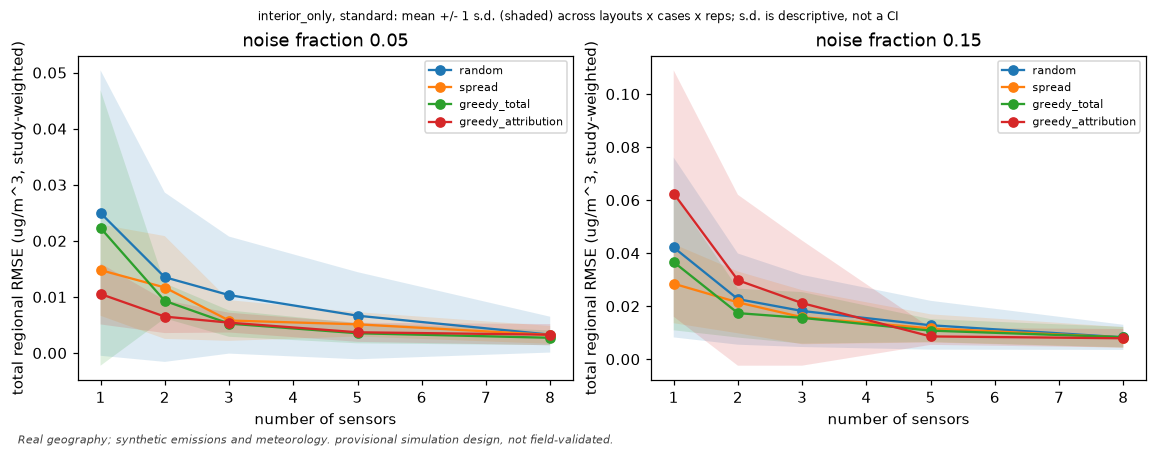

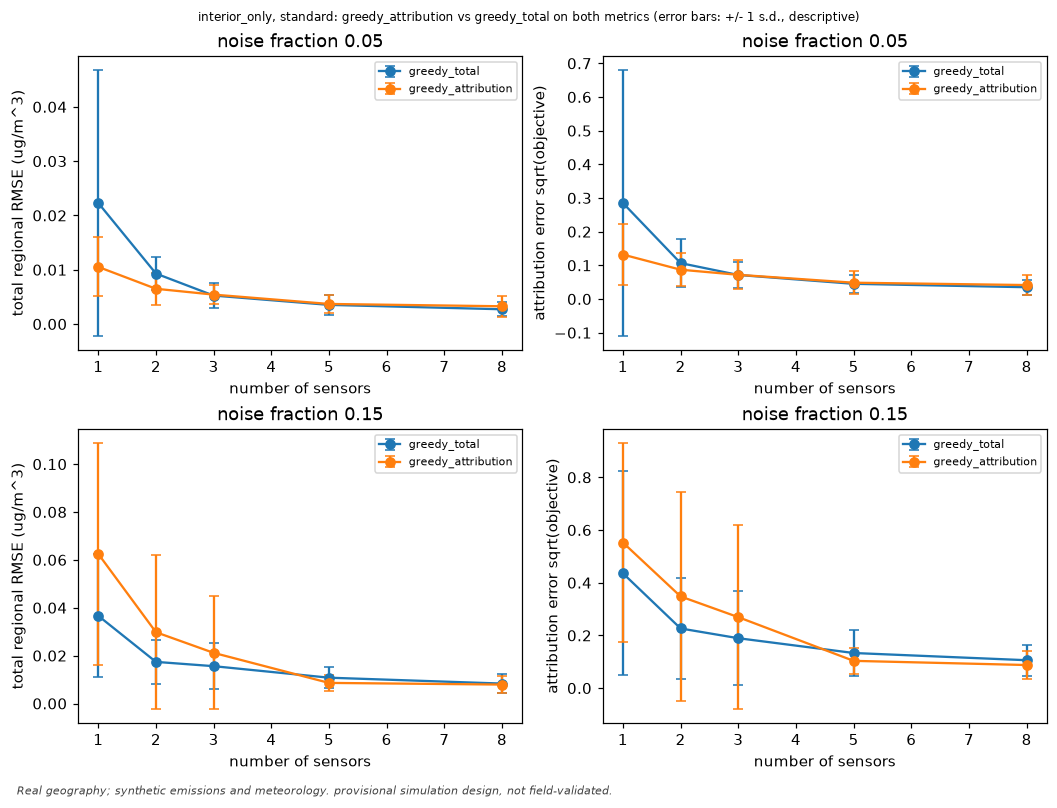

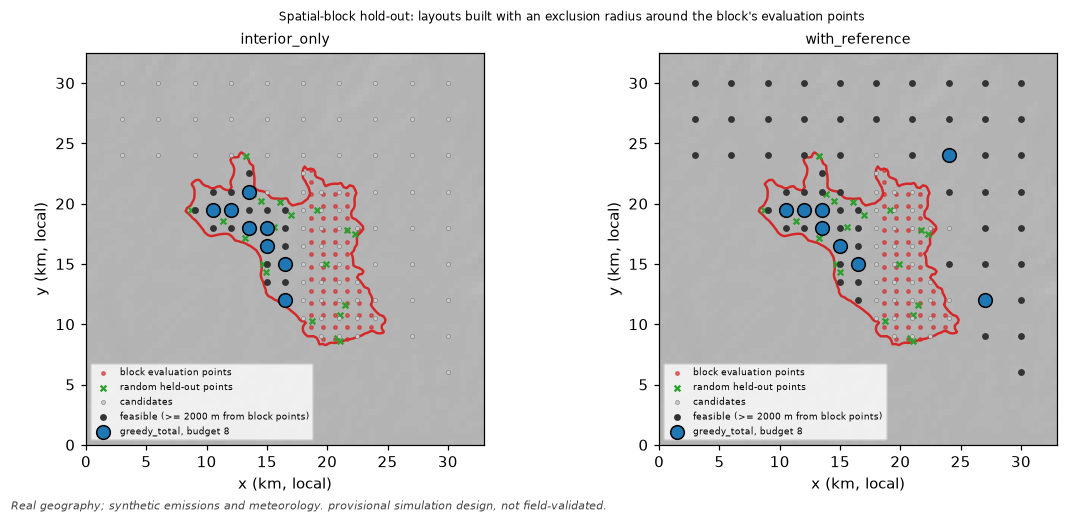

condition,boundary_time_profile,hidden_wind_error,omitted_external,omitted_facility,refined_truth,unseen_wind,unseen_wind_declared
budget,,,,,,,
1,-0.0002,0.0213,0.0010,0.0080,0.0022,0.0223,-0.0049
2,-0.0001,0.0292,0.0015,0.0077,0.0017,0.0325,0.0035
3,0.0002,0.0389,0.0019,0.0092,0.0029,0.0360,-0.0006
5,0.0007,0.0427,0.0012,0.0121,0.0045,0.0378,-0.0002
8,0.0009,0.0285,0.0014,0.0118,0.0039,0.0267,0.0001


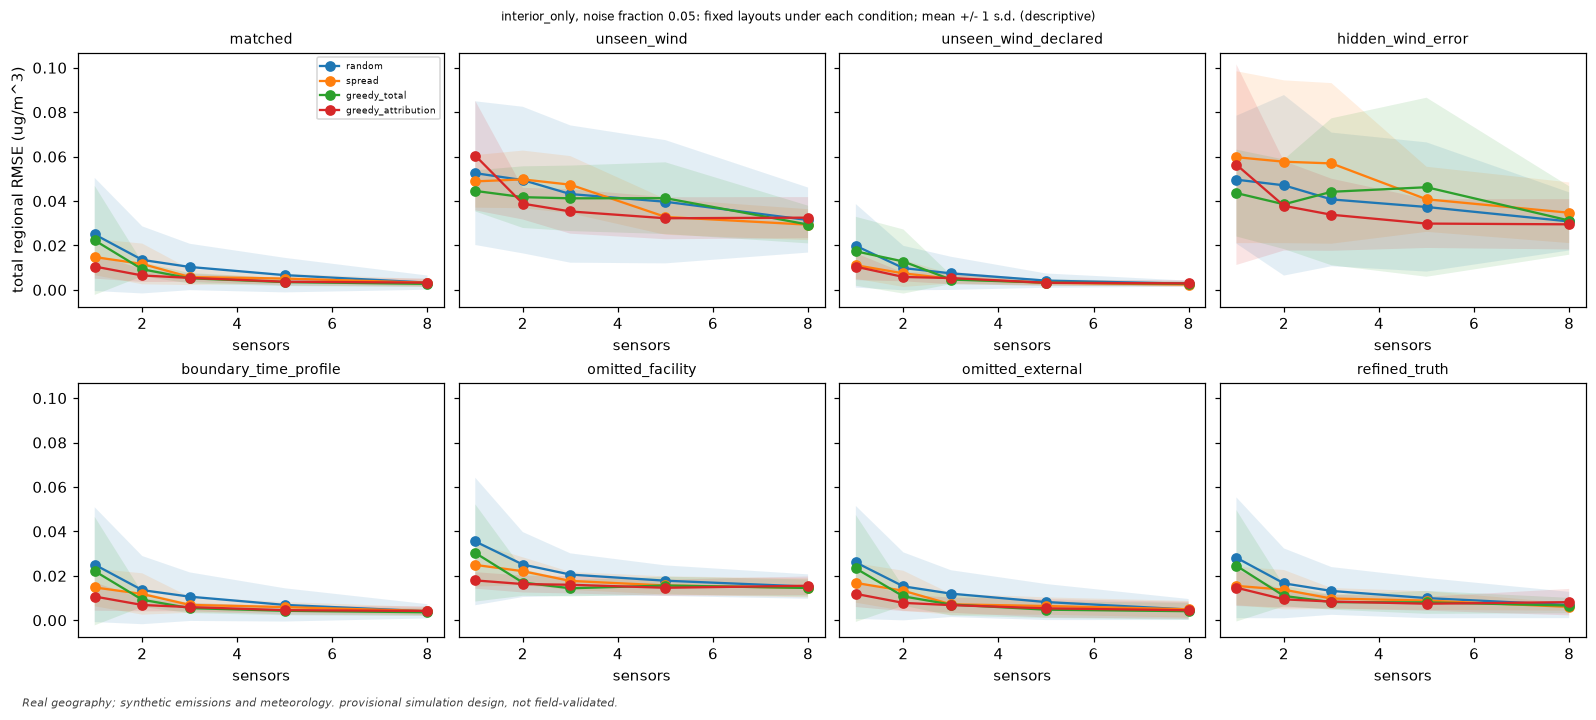

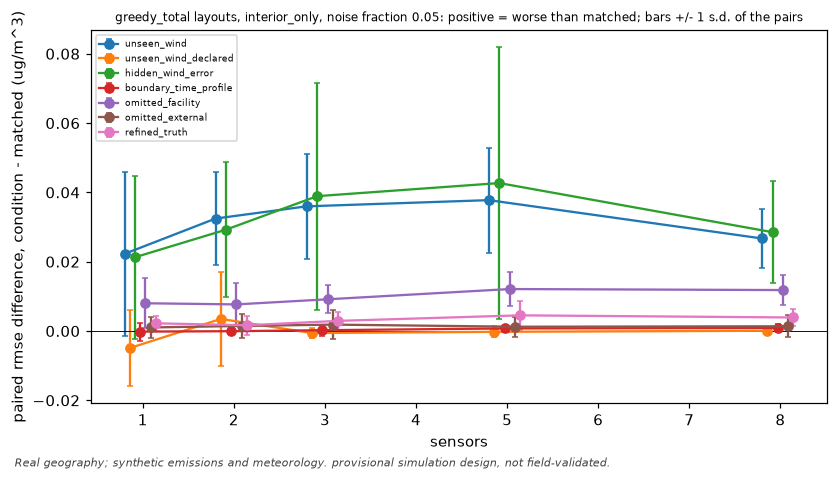

In [14]:
prod = root / "results" / "geodesign"
if (prod / "summary.csv").exists() and (prod / "figures").is_dir():
    ps_ = pd.read_csv(prod / "summary.csv")
    print("production study:", prod.name, "|", len(pd.read_csv(prod / "layouts.csv")), "layouts")
    v = ps_[(ps_.setting == "interior_only") & (ps_.regime == "standard") & (ps_.alpha_label == "selected")]
    display(v.pivot_table(index="budget", columns=["noise_fraction", "method"], values="mean_rmse").round(4))
    for fig_name in ("selected_sites.png", "error_vs_count_interior_only.png", "attribution_vs_total.png", "heldout_block_map.png"):
        if (prod / "figures" / fig_name).exists():
            display(Image(filename=str(prod / "figures" / fig_name)))
    pr = root / "results" / "geodesign-robust"
    if (pr / "paired_mismatch.csv").exists():
        pm = pd.read_csv(pr / "paired_mismatch.csv")
        x = pm[(pm.metric == "rmse") & (pm.method == "greedy_total") & (pm.setting == "interior_only") & (pm.noise_fraction == pm.noise_fraction.min())]
        display(x.pivot_table(index="budget", columns="condition", values="mean_diff").round(4))
        for fig_name in ("rmse_by_condition_interior_only.png", "paired_difference.png"):
            if (pr / "figures" / fig_name).exists():
                display(Image(filename=str(pr / "figures" / fig_name)))
else:
    print("no complete production run under results/geodesign: nothing to show (the smoke results above stand in)")

## 12. What these results are, and are not

* **Real geography; synthetic emissions and meteorology.** All emissions, winds, inflow and noise are synthetic; only the geometry is real.
* The layouts are **provisional simulation designs, not field-validated deployment instructions.** Mapped accessibility is not permission, power, security or connectivity; OSM gaps are not absence of feasible sites; reference sites are only as realistic as the Nepal ADM0 outline, and anything across the border is hypothetical.
* Greedy layouts are heuristics, not optimal; they depend on the few design cases drawn.
* The matched experiments are idealised (known wind, K, lam, H, source shapes and onsets). The robustness conditions test some departures one at a time; they do not cover terrain-driven flow, unknown source shapes or instrument bias.
* With a handful of cases and noise repetitions the differences between methods are descriptive, not statistical conclusions.
* The physical K = 100 m2/s is not tuned; the numerical spreading of the scheme (K_eff/K above) is reported separately and affects every model in the study.
* A field campaign should treat these layouts as candidates to be re-examined with measurements.

Total notebook time so far: see the next cell.

In [15]:
print(f"notebook wall time: {time.perf_counter() - T0:.0f} s")

notebook wall time: 193 s
